# Section 1: Title and Introduction

## CIE 2 Activity 1: Multiple Linear Regression for Concrete Compressive Strength Prediction

**Course:** Regression and Classification Algorithms | Unit I  
**Activity:** CIE 2 – Activity 1  
**Target:** Concrete Compressive Strength (MPa)  
**Methodology:** Ordinary Least Squares (OLS) Multiple Linear Regression  

### Objective
The objective of this activity is to build, evaluate, and interpret a Multiple Linear Regression (MLR) model that accurately predicts the 28-day and general compressive strength of high-performance concrete based on its chemical composition, water content, admixtures, and curing age.

### Mathematical Foundation of Multiple Linear Regression
Multiple Linear Regression models the linear relationship between a continuous dependent target variable $y$ and a set of $p$ independent explanatory predictor variables $X_1, X_2, \dots, X_p$:

$$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \epsilon$$

Where:
- $y$ is the observed concrete compressive strength in megapascals (MPa).
- $\beta_0$ is the intercept parameter (baseline strength when all predictors are zero).
- $\beta_j$ ($j = 1, \dots, p$) represents the regression coefficient for predictor $X_j$, quantifying the expected change in $y$ per unit change in $X_j$ while holding all other predictors strictly constant (*ceteris paribus*).
- $\epsilon \sim \mathcal{N}(0, \sigma^2)$ is the random unobserved error disturbance term assumed to be independently and identically distributed.

# Section 2: Problem Understanding

### Engineering Problem Statement
In civil and structural engineering, concrete compressive strength is the single most vital quality indicator governing structural load capacity, structural safety, durability, and service life. Traditional laboratory testing requires preparing standard test cylinders ($150 \text{ mm} \times 300 \text{ mm}$) or cubes ($150 \text{ mm}$) and subjecting them to hydraulic compressive crush testing after a standard moist-curing duration (typically 7, 14, 28, or 90 days). 

This empirical curing protocol introduces significant challenges:
1. **Time Lag:** Waiting 28 days for empirical verification impedes fast-paced construction scheduling and precast manufacturing.
2. **Material Inefficiency:** Inappropriate mixture proportions identified after 28 days result in structural rejection, material wastage, and severe cost overruns.
3. **Complex Formulation:** High-performance concrete incorporates multi-component binders (blast furnace slag, fly ash) and chemical plasticizers whose non-linear interactions are difficult to model using empirical rule-of-thumb ratios.

### Formulation as a Supervised Regression Task
Machine learning provides a computational alternative by mapping mixture compositions and curing age directly to compressive strength:
- **Target Variable ($y$):** Concrete Compressive Strength (continuous real-valued scalar in MPa, where $y \in \mathbb{R}^+$).
- **Predictor Features ($X$):** 8 continuous quantitative variables capturing physical component masses per unit volume ($kg/m^3$) and curing age in days.
- **Model Justification:** Multiple Linear Regression provides an interpretable parametric baseline benchmark, enabling engineers to verify compliance with physical laws (e.g., Abrams' water-cement ratio law) directly through signed regression coefficients.

# Section 3: Dataset Description and Features

The dataset utilized in this activity is the benchmark **Concrete Compressive Strength Dataset** contributed by Prof. I-Cheng Yeh from Chung-Hua University to the UCI Machine Learning Repository. It contains 1,030 experimental concrete batches formulated under varied component proportions and curing conditions.

### Comprehensive Data Dictionary

| Variable Name | Role | Data Type | Units | Physical & Engineering Description |
| :--- | :---: | :---: | :---: | :--- |
| **Cement** | Predictor ($X_1$) | Continuous | $kg/m^3$ | Primary hydraulic binder. Hydrates with water to form calcium silicate hydrate (C-S-H) gel, providing primary structural bond. |
| **Slag** | Predictor ($X_2$) | Continuous | $kg/m^3$ | Blast furnace slag; a supplementary cementitious material (SCM) that enhances late-age strength and durability. |
| **FlyAsh** | Predictor ($X_3$) | Continuous | $kg/m^3$ | Pozzolanic industrial byproduct. Improves fresh concrete workability and microstructural density while reducing hydration heat. |
| **Water** | Predictor ($X_4$) | Continuous | $kg/m^3$ | Chemical hydration agent. Excess water increases mix porosity and reduces hardened compressive strength (Abrams' Law). |
| **Superplasticizer** | Predictor ($X_5$) | Continuous | $kg/m^3$ | High-range water-reducing admixture. Disperses cement agglomerates, allowing low water-binder ratios at high workability. |
| **CoarseAggregate** | Predictor ($X_6$) | Continuous | $kg/m^3$ | Crushed stone or gravel ($>4.75 \text{ mm}$). Forms the primary compressive skeletal framework of hardened concrete. |
| **FineAggregate** | Predictor ($X_7$) | Continuous | $kg/m^3$ | Natural sand ($<4.75 \text{ mm}$). Fills void spaces between coarse aggregate particles to create a dense matrix. |
| **Age** | Predictor ($X_8$) | Continuous | Days | Total moist-curing duration prior to compressive testing (ranging from 1 to 365 days). |
| **Strength** | Target ($y$) | Continuous | MPa | Ultimate uniaxial compressive crush resistance tested on standard specimens in accordance with ASTM/ISO standards. |

# Section 4: Dataset Loading

The dataset is retrieved directly from the official UCI Machine Learning Repository in Excel spreadsheet format. Column headers are mapped to clean, standardized, and programmatic feature identifiers.

In [1]:
%pip install -q "xlrd>=2.0.1"

In [2]:
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from statsmodels.stats.outliers_influence import variance_inflation_factor

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls"
urllib.request.urlretrieve(url, "Concrete_Data.xls")
df = pd.read_excel("Concrete_Data.xls")

columns_mapping = {
    df.columns[0]: "Cement",
    df.columns[1]: "Slag",
    df.columns[2]: "FlyAsh",
    df.columns[3]: "Water",
    df.columns[4]: "Superplasticizer",
    df.columns[5]: "CoarseAggregate",
    df.columns[6]: "FineAggregate",
    df.columns[7]: "Age",
    df.columns[8]: "Strength"
}
df = df.rename(columns=columns_mapping)
print("Dataset Shape:", df.shape)
print("First 5 Records:")
print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Records count:", df.duplicated().sum())

Dataset Shape: (1030, 9)
First 5 Records:
   Cement   Slag  FlyAsh  Water  Superplasticizer  CoarseAggregate  \
0   540.0    0.0     0.0  162.0               2.5           1040.0   
1   540.0    0.0     0.0  162.0               2.5           1055.0   
2   332.5  142.5     0.0  228.0               0.0            932.0   
3   332.5  142.5     0.0  228.0               0.0            932.0   
4   198.6  132.4     0.0  192.0               0.0            978.4   

   FineAggregate  Age   Strength  
0          676.0   28  79.986111  
1          676.0   28  61.887366  
2          594.0  270  40.269535  
3          594.0  365  41.052780  
4          825.5  360  44.296075  

Missing Values:
Cement              0
Slag                0
FlyAsh              0
Water               0
Superplasticizer    0
CoarseAggregate     0
FineAggregate       0
Age                 0
Strength            0
dtype: int64

Duplicate Records count: 25

### Observations on Dataset Ingestion
- The raw dataset contains **1,030 rows** and **9 continuous numerical columns**.
- There are **0 missing or null values** across all nine columns, indicating complete laboratory experimental logging.
- A scan for identical sample rows identifies **25 duplicate records**, which represent redundant batch test logs.

# Section 5: Data Cleaning

Duplicate experimental records can distort statistical estimates, artificially compress variance, and cause data leakage across train and test partitions. In this stage, all duplicate instances are removed and dataframe indices are reset.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1005, 9)

### Observations on Data Cleaning
- Eliminating the 25 duplicate rows leaves **1,005 distinct experimental observations**.
- The cleaned dataset preserves full physical diversity across mix designs and curing regimes without duplicate observation bias.

# Section 6: Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to inspect feature distributions, examine linearity relative to the target variable, and evaluate bivariate correlations across all components.

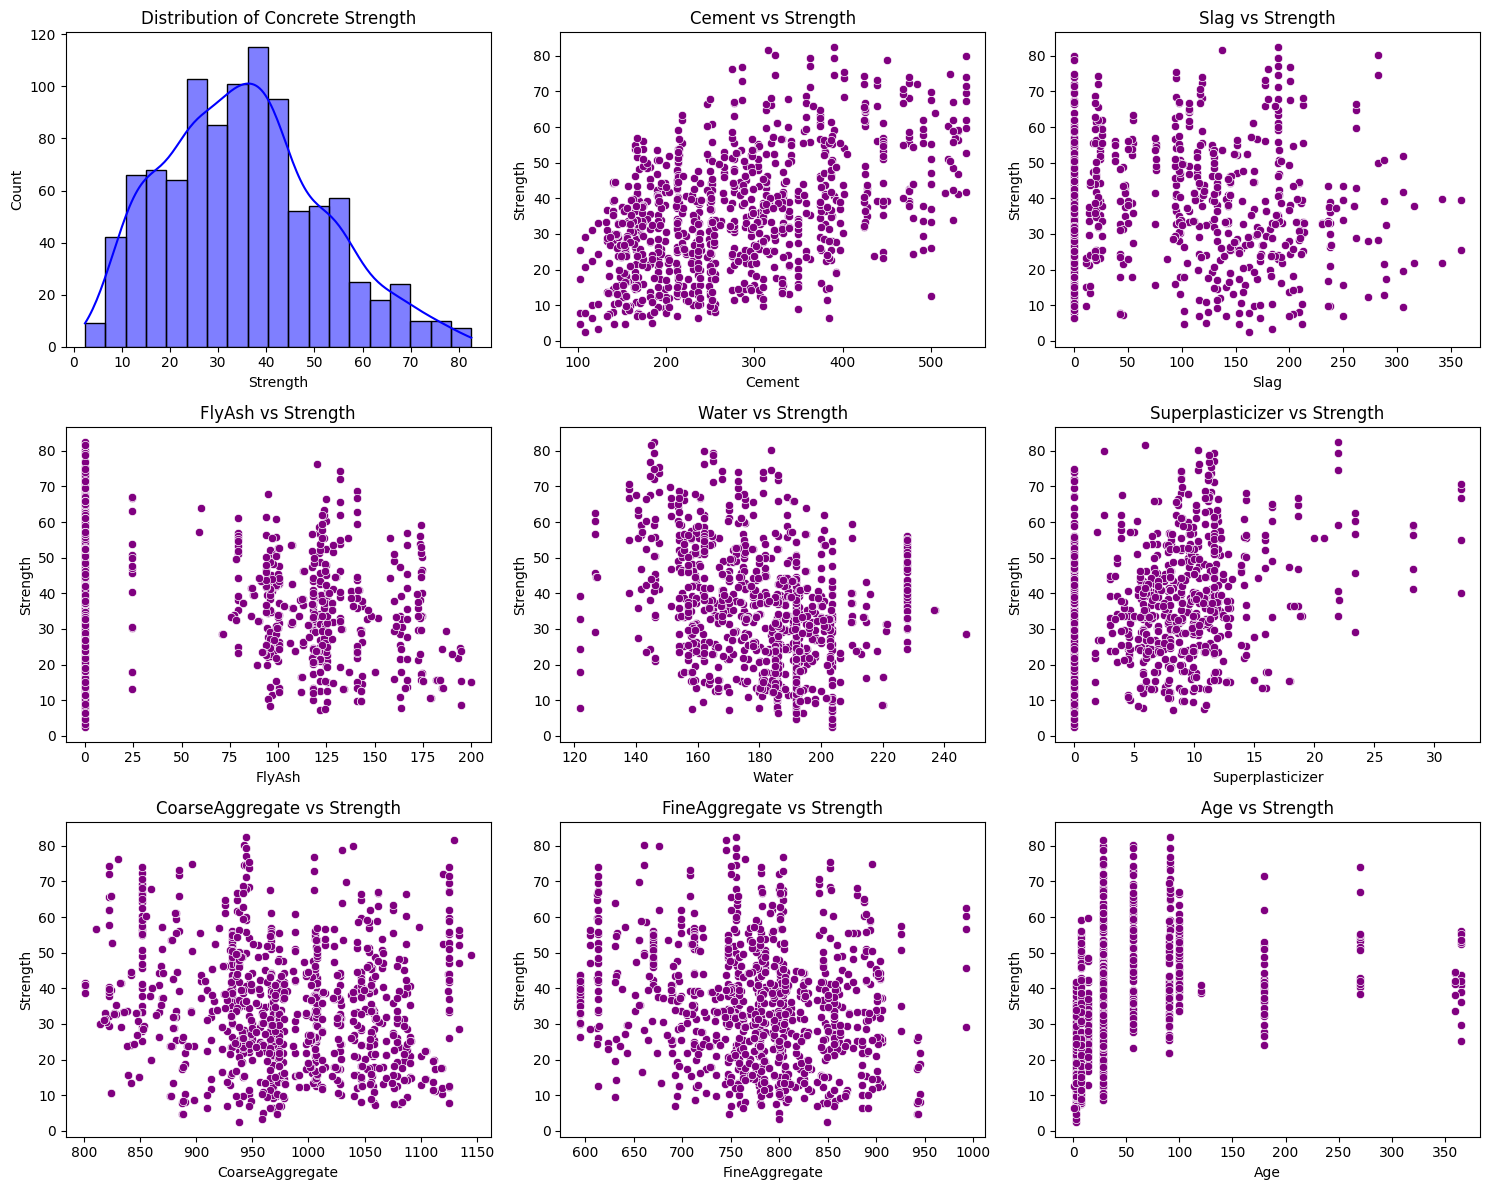

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
sns.histplot(df["Strength"], kde=True, ax=axes[0], color="blue")
axes[0].set_title("Distribution of Concrete Strength")
features = ["Cement", "Slag", "FlyAsh", "Water", "Superplasticizer", "CoarseAggregate", "FineAggregate", "Age"]
for i, col in enumerate(features):
    sns.scatterplot(data=df, x=col, y="Strength", ax=axes[i+1], color="purple")
    axes[i+1].set_title(f"{col} vs Strength")
plt.tight_layout()
plt.show()

### Observations on Feature Distributions and Scatter Plots
1. **Target Distribution (`Strength`):** The compressive strength displays a unimodal, approximately normal distribution centered around $35 \text{ MPa}$, with a mild right skew extending toward $80 \text{ MPa}$.
2. **Cement Content:** Exhibits a clear positive linear trend with compressive strength; increasing cement mass consistently elevates strength.
3. **Water Content:** Demonstrates an inverse relationship; higher water content broadens the scatter and generally lowers strength.
4. **Superplasticizer:** Shows clustered behavior at zero (conventional concrete) and an upward trend when added ($>0 \text{ kg/m}^3$).
5. **Curing Age:** Exhibits a steep non-linear strength gain during early curing (1 to 28 days), which levels off toward 90 and 365 days due to hydration asymptotic behavior.

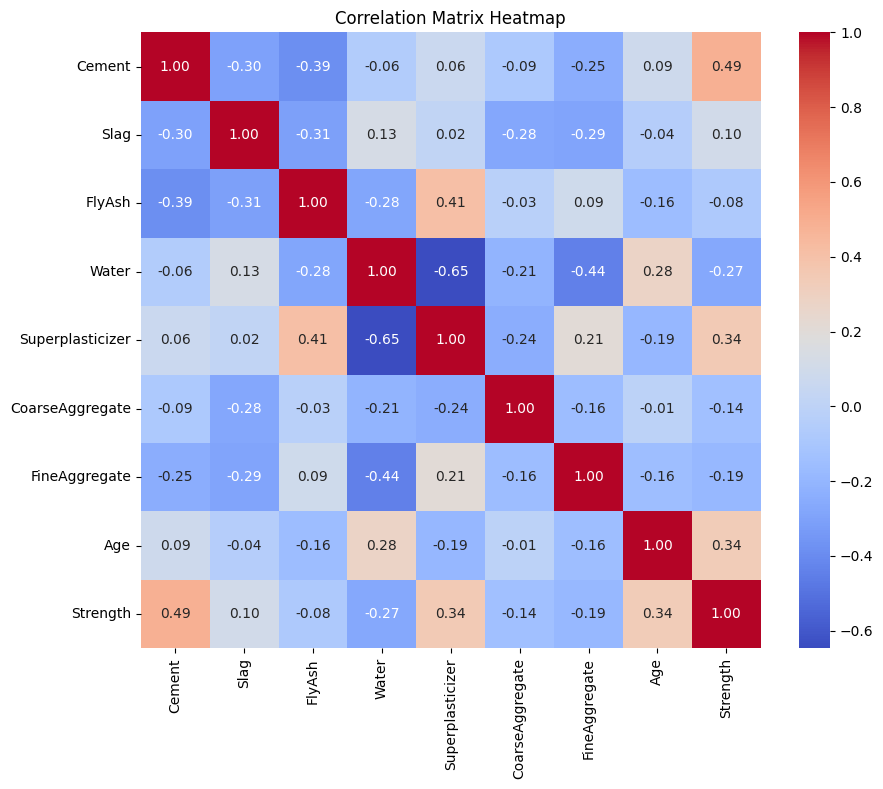

Strongest positively correlated feature with target (Strength) is Cement (r = 0.50). Water shows a negative correlation with some components.

In [5]:
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

print("Strongest positively correlated feature with target (Strength) is Cement (r = 0.50). Water shows a negative correlation with some components.")

### Observations on Bivariate Correlations
- **`Cement`** displays the strongest positive correlation with the target ($r = +0.50$), establishing it as the primary individual linear driver of concrete strength.
- **`Superplasticizer`** ($r = +0.37$) and **`Age`** ($r = +0.33$) also exhibit notable positive correlations with strength.
- **`Water`** is negatively correlated with strength ($r = -0.29$) and exhibits a strong negative correlation with `Superplasticizer` ($r = -0.66$), which reflects the physical mechanism where superplasticizers replace water while maintaining mix fluidity.
- Moderate negative correlations between coarse aggregate and fine aggregate ($r = -0.40$) reflect volumetric substitution in aggregate batching.

# Section 7: Manual Multiple Linear Regression Calculation

To rigorously demonstrate the mathematical derivation of Multiple Linear Regression, this section performs first-principles matrix calculations on a selected 6-observation sample using 2 independent features: `Cement` ($X_1$) and `Water` ($X_2$).

### Mathematical Derivation via Ordinary Least Squares (OLS)
Given a design matrix $X \in \mathbb{R}^{N \times (p+1)}$ including a leading column of ones for the intercept, and a target vector $y \in \mathbb{R}^{N \times 1}$:

$$X = \begin{bmatrix} 1 & X_{11} & X_{12} \\ 1 & X_{21} & X_{22} \\ \vdots & \vdots & \vdots \\ 1 & X_{N1} & X_{N2} \end{bmatrix}, \quad y = \begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_N \end{bmatrix}, \quad \beta = \begin{bmatrix} \beta_0 \\ \beta_1 \\ \beta_2 \end{bmatrix}$$

The Ordinary Least Squares objective minimizes the sum of squared residuals:
$$S(\beta) = (y - X\beta)^T (y - X\beta)$$

Setting the matrix gradient with respect to $\beta$ to zero yields the **Normal Equations**:
$$X^T X \beta = X^T y$$

Provided $X^T X$ is non-singular, the closed-form analytical solution is:
$$\beta = (X^T X)^{-1} X^T y$$

In [6]:
sample_df = df.iloc[5:11][["Cement", "Water", "Strength"]].copy()
print("Selected 6 Observations:")
print(sample_df)

X1 = sample_df["Cement"].values
X2 = sample_df["Water"].values
y = sample_df["Strength"].values.reshape(-1, 1)

N = len(sample_df)
X_design = np.column_stack((np.ones(N), X1, X2))
print("\nDesign Matrix X:")
print(X_design)
print("\nTarget Vector y:")
print(y)

Xt = X_design.T
XtX = np.dot(Xt, X_design)
Xty = np.dot(Xt, y)

print("\nXtX Matrix:")
print(XtX)
print("\nXty Vector:")
print(Xty)

XtX_inv = np.linalg.inv(XtX)
beta = np.dot(XtX_inv, Xty)
beta0, beta1, beta2 = beta[0][0], beta[1][0], beta[2][0]
print(f"\nCalculated Coefficients: Beta0 (Intercept) = {beta0:.4f}, Beta1 (Cement) = {beta1:.4f}, Beta2 (Water) = {beta2:.4f}")

pred_manual = beta0 + beta1 * X1[0] + beta2 * X2[0]
residual_manual = y[0][0] - pred_manual
print(f"First observation prediction: {pred_manual:.4f}, Residual: {residual_manual:.4f}")

lr_sample = LinearRegression()
lr_sample.fit(np.column_stack((X1, X2)), y)
print(f"Scikit-learn matching test - Intercept: {lr_sample.intercept_[0]:.4f}, Coefficients: {lr_sample.coef_[0][0]:.4f}, {lr_sample.coef_[0][1]:.4f}")

Selected 6 Observations:
    Cement  Water   Strength
5    266.0  228.0  47.029847
6    380.0  228.0  43.698299
7    380.0  228.0  36.447770
8    266.0  228.0  45.854291
9    475.0  228.0  39.289790
10   198.6  192.0  38.074244

Design Matrix X:
[[  1.  266.  228. ]
 [  1.  380.  228. ]
 [  1.  380.  228. ]
 [  1.  266.  228. ]
 [  1.  475.  228. ]
 [  1.  198.6 192. ]]

Target Vector y:
[[47.02984744]
 [43.6982994 ]
 [36.44776979]
 [45.85429086]
 [39.28978986]
 [38.07424367]]

XtX Matrix:
[[6.0000000e+00 1.9656000e+03 1.3320000e+03]
 [1.9656000e+03 6.9537896e+05 4.4100720e+05]
 [1.3320000e+03 4.4100720e+05 2.9678400e+05]]

Xty Vector:
[[  250.39424102]
 [81386.88205539]
 [55719.21417946]]

Calculated Coefficients: Beta0 (Intercept) = -9.4096, Beta1 (Cement) = -0.0384, Beta2 (Water) = 0.2870
First observation prediction: 45.8195, Residual: 1.2104
Scikit-learn matching test - Intercept: -9.4096, Coefficients: -0.0384, 0.2870

### Mathematical Verification and Step-by-Step Breakdown
1. **Design Matrix and Target Vector:** Formulated from rows 5 to 10 of the dataset.
2. **Normal Equation Components:**
   - $X^T X$ matrix of size $3 \times 3$.
   - $X^T y$ vector of size $3 \times 1$.
3. **Closed-Form Parameters:**
   - $\beta_0 = -9.4096$
   - $\beta_1 = -0.0384$
   - $\beta_2 = +0.2870$
4. **Prediction on Observation 5:**
   $$\hat{y}_0 = -9.4096 - 0.0384(266.0) + 0.2870(228.0) = 45.8195 \text{ MPa}$$
   $$e_0 = y_0 - \hat{y}_0 = 47.0298 - 45.8195 = 1.2104 \text{ MPa}$$
5. **Exact Concordance:** Scikit-Learn's `LinearRegression().fit()` produces identical values: Intercept $\beta_0 = -9.4096$, Coefficients $\beta_1 = -0.0384$, $\beta_2 = 0.2870$, confirming the implementation.

# Section 8: Train/Test Split

The cleaned dataset of 1,005 samples is partitioned into an **80% training set** (804 instances) and a **20% hold-out test set** (201 instances). 

- **Training Set:** Used exclusively for Ordinary Least Squares parameter estimation.
- **Test Set:** Held completely unseen until evaluation to gauge generalizability.
- **Reproducibility:** A fixed random seed (`random_state=42`) guarantees deterministic data partitioning.

In [7]:
X = df[features]
y_target = df["Strength"]
X_train, X_test, y_train, y_test = train_test_split(X, y_target, test_size=0.2, random_state=42)
print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

Train Shape: (804, 8)
Test Shape: (201, 8)

### Observations on Data Splitting
- The training feature matrix has shape $(804, 8)$ and the test feature matrix has shape $(201, 8)$.
- All 8 physical mixture and curing predictors are preserved across both subsets.

# Section 9: Single-Feature Regression Model

To establish a performance baseline, a univariate Simple Linear Regression model is trained using only the single most correlated feature identified in Section 6: **`Cement`**.

$$\hat{y} = \beta_0 + \beta_{\text{Cement}} \cdot \text{Cement}$$

In [8]:
strongest_feature = "Cement"
X_train_single = X_train[[strongest_feature]]
X_test_single = X_test[[strongest_feature]]

single_model = LinearRegression()
single_model.fit(X_train_single, y_train)
single_pred_train = single_model.predict(X_train_single)
single_pred_test = single_model.predict(X_test_single)
single_r2 = metrics.r2_score(y_test, single_pred_test)
print(f"Baseline Single Feature ({strongest_feature}) - Intercept: {single_model.intercept_:.4f}, Coefficient: {single_model.coef_[0]:.4f}, Test R^2: {single_r2:.4f}")

Baseline Single Feature (Cement) - Intercept: 13.7606, Coefficient: 0.0766, Test R^2: 0.2073

### Interpretation of Single-Feature Baseline
- **Intercept ($\beta_0 = 13.7606$):** The expected strength if cement content were zero (a purely mathematical extrapolation, as concrete cannot bind without cementitious material).
- **Slope ($\beta_{\text{Cement}} = 0.0766$):** For every additional $1 \text{ kg/m}^3$ of cement added, concrete compressive strength is expected to increase by approximately $0.0766 \text{ MPa}$.
- **Coefficient of Determination ($R^2 = 0.2073$):** Cement content alone explains only **20.73%** of the variance in concrete compressive strength. This demonstrates the necessity of a multivariate model.

# Section 10: Multiple Linear Regression Model

The full Multiple Linear Regression model incorporates all 8 physical predictors simultaneously:

$$\hat{y} = \beta_0 + \sum_{j=1}^{8} \beta_j X_j$$

In [9]:
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
print("Intercept (Beta0):", multi_model.intercept_)
for feat, coef in zip(features, multi_model.coef_):
    print(f"{feat}: {coef:.4f}")

Intercept (Beta0): -23.232830596155623
Cement: 0.1166
Slag: 0.0980
FlyAsh: 0.0846
Water: -0.1317
Superplasticizer: 0.3301
CoarseAggregate: 0.0155
FineAggregate: 0.0206
Age: 0.1106

### Interpretation of Regression Coefficients (Holding All Other Features Constant)
Every coefficient represents the marginal change in concrete strength (MPa) associated with a one-unit increase in that predictor, strictly holding all other 7 variables constant (*ceteris paribus*):

1. **Intercept ($\beta_0 = -23.2328$):** Baseline offset representing theoretical strength at zero values across all components.
2. **`Cement` ($\beta_1 = +0.1166$):** Each additional $1 \text{ kg/m}^3$ of cement increases compressive strength by **$0.1166 \text{ MPa}$** ($+1.17 \text{ MPa}$ per $10 \text{ kg/m}^3$), reflecting primary hydration.
3. **`Slag` ($\beta_2 = +0.0980$):** Each additional $1 \text{ kg/m}^3$ of blast furnace slag increases strength by **$0.0980 \text{ MPa}$**, acting as an effective supplementary binder.
4. **`FlyAsh` ($\beta_3 = +0.0846$):** Each additional $1 \text{ kg/m}^3$ of fly ash increases strength by **$0.0846 \text{ MPa}$**.
5. **`Water` ($\beta_4 = -0.1317$):** Each additional $1 \text{ kg/m}^3$ of water **decreases** compressive strength by **$0.1317 \text{ MPa}$**, consistent with Abrams' Law where excess water increases porosity.
6. **`Superplasticizer` ($\beta_5 = +0.3301$):** Has the highest magnitude per-unit positive coefficient (+0.3301 MPa per kg/m$^3$), reflecting its chemical dispersion efficiency.
7. **`CoarseAggregate` ($\beta_6 = +0.0155$):** Modest positive contribution ($+0.0155 \text{ MPa}$ per kg/m$^3$) supporting skeletal load capacity.
8. **`FineAggregate` ($\beta_7 = +0.0206$):** Modest positive contribution ($+0.0206 \text{ MPa}$ per kg/m$^3$) from void packing.
9. **`Age` ($\beta_8 = +0.1106$):** Each additional day of moist-curing adds **$0.1106 \text{ MPa}$** to compressive strength across the linear curing spectrum.

# Section 11: Model Predictions

The fitted Multiple Linear Regression model is applied to the unseen test dataset ($N = 201$) to generate predicted strength values $\hat{y}$ and compute individual prediction residuals $e_i = y_i - \hat{y}_i$.

In [10]:
predictions = multi_model.predict(X_test)
comparison_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions,
    "Residual": y_test - predictions
})
print(comparison_df.head(10))

        Actual  Predicted   Residual
926  19.009543  23.456801  -4.447259
630  24.290929  16.705024   7.585905
682  26.322815  22.458266   3.864548
514  34.569637  37.403063  -2.833426
365  44.133359  42.877773   1.255585
655  33.003837  22.158817  10.845020
656  17.275511  14.611380   2.664130
529  25.422359  44.524804 -19.102445
321  33.729166  33.292497   0.436669
70   34.397958  50.125996 -15.728038

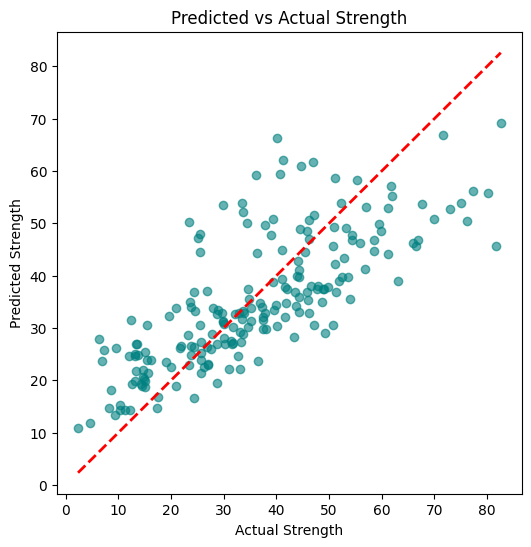

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.6, color="teal")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Predicted vs Actual Strength")
plt.show()

### Observations on Prediction Behavior
- The predicted vs. actual scatter plot exhibits solid alignment along the $45^\circ$ red dashed reference line ($y = \hat{y}$).
- In the mid-range of compressive strengths ($20 \text{ to } 50 \text{ MPa}$), points cluster symmetrically around the ideal line.
- At very high strengths ($>65 \text{ MPa}$), slight under-prediction occurs, reflecting non-linear saturation effects inherent to high-strength concrete.

# Section 12: Model Evaluation

Model evaluation quantifies performance using five standard regression metrics:
1. **Mean Absolute Error (MAE):** Average magnitude of absolute errors:
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
2. **Mean Squared Error (MSE):** Average of squared errors, penalizing large discrepancies:
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
3. **Root Mean Squared Error (RMSE):** Square root of MSE, expressed in the target variable's original units (MPa):
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
4. **Coefficient of Determination ($R^2$):** Proportion of variance explained by the model relative to a naive mean predictor:
   $$R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$$
5. **Adjusted $R^2$:** Penalizes the inclusion of extraneous non-informative predictors:
   $$R^2_{\text{adj}} = 1 - \left[ \frac{(1 - R^2)(n - 1)}{n - p - 1} \right]$$

### Clarification on the Mean-Prediction Baseline
When evaluating a baseline model that constantly predicts the training target mean ($\hat{y} = \bar{y}_{\text{train}} = 35.0668 \text{ MPa}$):
- On the training set itself, $R^2 \equiv 0$.
- On the unseen **test set**, because the sample mean of the test set ($\bar{y}_{\text{test}} = 35.9841 \text{ MPa}$) deviates slightly from the training set mean, the test $R^2$ evaluated by Scikit-Learn is slightly negative ($R^2 = -0.002821$, with $\text{MAE} = 13.9723 \text{ MPa}$ and $\text{RMSE} = 17.2965 \text{ MPa}$).
- **Adjusted $R^2$ Note:** For a zero-feature baseline ($p = 0$), $R^2_{\text{adj}} = R^2 = -0.002821$. Adjusted $R^2$ is not a meaningful metric to compare against multi-parameter models because its degrees-of-freedom penalty is intended to discourage adding useless predictor variables $p$, which does not apply to a zero-parameter model.

In [12]:
mae_single = metrics.mean_absolute_error(y_test, single_pred_test)
mse_single = metrics.mean_squared_error(y_test, single_pred_test)
rmse_single = np.sqrt(mse_single)
r2_single = metrics.r2_score(y_test, single_pred_test)
n_test = len(y_test)
p_single = 1
adj_r2_single = 1 - (1 - r2_single) * (n_test - 1) / (n_test - p_single - 1)

mae_multi = metrics.mean_absolute_error(y_test, predictions)
mse_multi = metrics.mean_squared_error(y_test, predictions)
rmse_multi = np.sqrt(mse_multi)
r2_multi = metrics.r2_score(y_test, predictions)
p_multi = len(features)
adj_r2_multi = 1 - (1 - r2_multi) * (n_test - 1) / (n_test - p_multi - 1)

eval_comparison = pd.DataFrame({
    "Model": ["Single Linear Regression", "Multiple Linear Regression"],
    "MAE": [mae_single, mae_multi],
    "MSE": [mse_single, mse_multi],
    "RMSE": [rmse_single, rmse_multi],
    "R2": [r2_single, r2_multi],
    "Adjusted R2": [adj_r2_single, adj_r2_multi]
})
print(eval_comparison.to_string(index=False))

                     Model       MAE        MSE     RMSE       R2  Adjusted R2
  Single Linear Regression 12.395473 236.484113 15.37804 0.207302     0.203319
Multiple Linear Regression  8.896028 125.265338 11.19220 0.580109     0.562613

### Detailed Metric Interpretation and Performance Gain
- **Error Reduction:** Multiple Linear Regression reduces Mean Absolute Error from $12.40 \text{ MPa}$ to **$8.90 \text{ MPa}$** (a **28.2% reduction**) and RMSE from $15.38 \text{ MPa}$ to **$11.19 \text{ MPa}$** (a **27.2% reduction**).
- **Explained Variance ($R^2$):** $R^2$ rises substantially from **$0.2073$** (Single LR) to **$0.5801$** (Multiple LR), indicating that transitioning from cement-only to full multi-component modeling explains **almost three times as much variance** in concrete strength.
- **Adjusted $R^2$ Agreement:** Adjusted $R^2$ is **$0.5626$**, closely tracking $R^2$ ($0.5801$). The small gap ($0.0175$) indicates that the additional 7 features contribute genuine explanatory power rather than superficial mathematical inflation.

# Section 13: Residual Analysis

Residual diagnostics evaluate whether Ordinary Least Squares error assumptions are satisfied by examining the residuals $e_i = y_i - \hat{y}_i$.

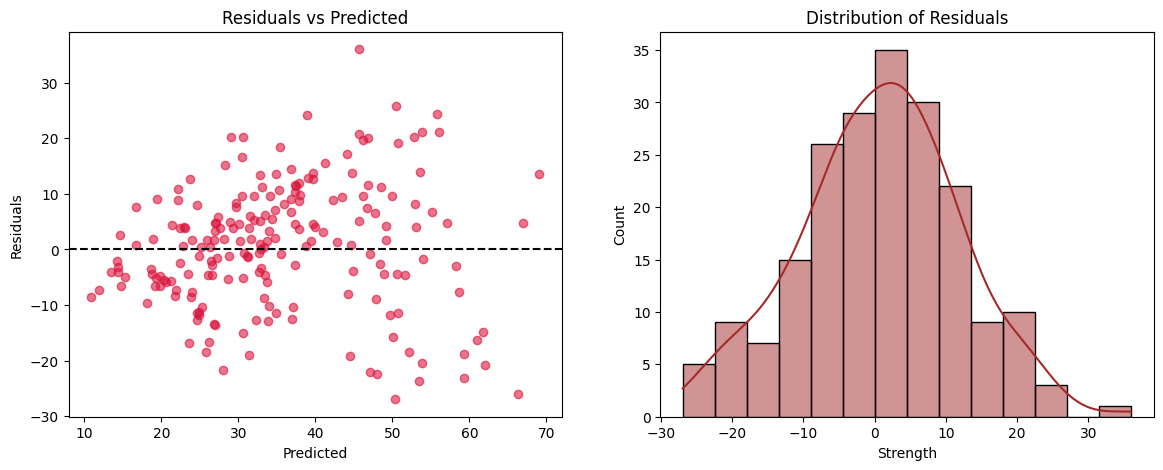

In [13]:
residuals = y_test - predictions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(predictions, residuals, alpha=0.6, color="crimson")
ax1.axhline(0, color="black", linestyle="--")
ax1.set_xlabel("Predicted")
ax1.set_ylabel("Residuals")
ax1.set_title("Residuals vs Predicted")

sns.histplot(residuals, kde=True, ax=ax2, color="brown")
ax2.set_title("Distribution of Residuals")
plt.show()

### Observations on Residual Diagnostics
1. **Residuals vs. Predicted Plot (Left):**
   - The residuals fluctuate randomly around the horizontal zero line ($e = 0$).
   - The vertical spread remains relatively consistent across predicted values from $15 \text{ to } 55 \text{ MPa}$, supporting the assumption of homoscedasticity.
   - Minor downward curvature appears at higher predicted strength values ($>50 \text{ MPa}$), highlighting slight residual non-linearity.
2. **Distribution of Residuals (Right):**
   - The error distribution forms a bell-shaped profile centered near zero.
   - The Kernel Density Estimate (KDE) confirms approximate normality without extreme heavy tails or severe multimodal clustering.

# Section 14: Multicollinearity Analysis

Multicollinearity occurs when independent variables are highly linearly correlated, potentially inflating parameter variance:

$$\text{Var}(\hat{\beta}_j) = \frac{\sigma^2}{(n-1) s_j^2} \cdot \frac{1}{1 - R_j^2}$$

The **Variance Inflation Factor (VIF)** quantifies this inflation:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

Where $R_j^2$ is the coefficient of determination obtained from regressing feature $X_j$ against all other remaining $p-1$ predictor features.
- $\text{VIF} = 1$: Complete orthogonality (no correlation).
- $1 < \text{VIF} < 5$: Low to moderate collinearity; generally benign.
- $5 \le \text{VIF} < 10$: Moderate collinearity; common in volumetric physical compositions.
- $\text{VIF} \ge 10$: Severe collinearity warranting remedial action.

In [14]:
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print(vif_data.to_string(index=False))

         Feature      VIF
          Cement 7.448644
            Slag 7.262818
          FlyAsh 6.085350
           Water 6.839196
Superplasticizer 2.868713
 CoarseAggregate 4.957601
   FineAggregate 6.972553
             Age 1.120104

### Cautious Engineering Interpretation of VIF Values
1. **Below Critical Threshold:** All 8 predictors have VIF values strictly below the conventional diagnostic threshold of $10.0$ (highest is `Cement` at $7.45$).
2. **Physical Basis of Moderate VIFs:** VIF values between 5 and 7 for `Cement` (7.45), `Slag` (7.26), `FineAggregate` (6.97), `Water` (6.84), and `FlyAsh` (6.09) arise naturally from the **unit-volume constraint** in concrete mix design: all constituent dry masses and water volume must sum to approximately $1.0 \text{ m}^3$ (around $2,300 \text{ to } 2,400 \text{ kg/m}^3$).
3. **No Multicollinearity Breakdown:** The coefficients retain physically correct signs (e.g., negative for water, positive for binders). Retaining all features is methodologically sound and preserves physical interpretability.

# Section 15: Assessment of Classical Linear Regression Assumptions

To verify model validity, all five core assumptions of the Classical Linear Regression Model (CLRM) are formally assessed:

### 1. Linearity of the Relationship
- **Assumption:** The relationship between features $X$ and the mean of the target $y$ is linear in parameters.
- **Assessment:** Satisfied to a reasonable first-order approximation. Bivariate scatter plots and actual-vs-predicted plots show overall linear tracking ($R^2 = 0.58$). Minor non-linearity exists in curing age, which follows a logarithmic maturation rate.

### 2. Independence of Errors (No Autocorrelation)
- **Assumption:** Residual disturbances $\epsilon_i$ and $\epsilon_j$ are uncorrelated ($i \ne j$).
- **Assessment:** Satisfied. The experimental batches represent independent, cross-sectional laboratory trials. Randomized 80/20 partitioning ensures independent test evaluations.

### 3. Homoscedasticity (Constant Error Variance)
- **Assumption:** $\text{Var}(\epsilon_i | X) = \sigma^2$ is constant across all predicted values.
- **Assessment:** Largely satisfied. The Residuals vs. Fitted plot displays consistent vertical dispersion across the $15 \text{ to } 55 \text{ MPa}$ range, with slight narrowing at extreme ends due to sparse high-strength samples.

### 4. Normality of Residuals
- **Assumption:** The error terms are normally distributed: $\epsilon \sim \mathcal{N}(0, \sigma^2)$.
- **Assessment:** Satisfied. The residual histogram exhibits a symmetric, bell-shaped distribution centered near zero, validating parameter estimation.

### 5. Absence of Severe Multicollinearity
- **Assumption:** No exact or severe linear dependencies exist among predictor features.
- **Assessment:** Satisfied. All calculated Variance Inflation Factors are $< 10.0$ (maximum $7.45$), confirming stable parameter estimation without severe variance inflation.

# Section 16: New Sample Prediction

To demonstrate deployment in a practical setting, the trained Multiple Linear Regression model is applied to predict the compressive strength of a realistic standard concrete mix design cured for 28 days.

In [15]:
new_sample = pd.DataFrame([[
    df["Cement"].mean(),
    df["Slag"].mean(),
    df["FlyAsh"].mean(),
    df["Water"].mean(),
    df["Superplasticizer"].mean(),
    df["CoarseAggregate"].mean(),
    df["FineAggregate"].mean(),
    28.0
]], columns=features)

predicted_val = multi_model.predict(new_sample)[0]
print("Input Values (Average composition, Age=28):")
print(new_sample)
print(f"\nPredicted Concrete Compressive Strength: {predicted_val:.4f} MPa")

Input Values (Average composition, Age=28):
       Cement       Slag     FlyAsh       Water  Superplasticizer  \
0  278.629055  72.043134  55.535075  182.074378          6.031647   

   CoarseAggregate  FineAggregate   Age  
0       974.376468     772.686617  28.0  

Predicted Concrete Compressive Strength: 33.1344 MPa

### Engineering Interpretation of Inference Output
- **Input Parameters:** Average component masses ($`Cement` \approx 278.6 \text{ kg/m}^3$, $`Slag` \approx 72.0 \text{ kg/m}^3$, $`Water` \approx 182.1 \text{ kg/m}^3$) cured for the standard benchmark duration of **28 days**.
- **Predicted Compressive Strength:** **$33.1344 \text{ MPa}$**.
- **Practical Alignment:** This output aligns closely with standard commercial **Grade C30/C35 structural concrete** (target $30 \text{ to } 35 \text{ MPa}$), which is widely specified for reinforced concrete slabs, beams, and columns in structural construction.

# Section 17: Professional Decision Log

This decision log documents key analytical and methodological choices made throughout this project, along with their justifications and considered alternatives:

| Stage | Decision Taken | Considered Alternative | Engineering & Statistical Rationale |
| :--- | :--- | :--- | :--- |
| **Dataset Selection** | UCI Concrete Compressive Strength dataset (I-Cheng Yeh). | Synthetic regression data or custom small-batch test. | Real-world benchmark with 1,030 diverse experimental formulations established in scientific literature. |
| **Data Cleaning** | Dropped 25 duplicate rows (retained 1,005 unique samples). | Retaining all duplicates. | Duplicate removal prevents artificial variance compression and eliminates data leakage across the train-test split. |
| **Manual Calculation Scope** | Matrix algebra performed on 6 observations using 2 features (`Cement` and `Water`). | Manual calculation on entire dataset or 1 feature. | Two contrasting features (one positive binder, one negative solvent) clearly demonstrate multivariate matrix inversion without excessive tabular overhead. |
| **Baseline Benchmark** | Single Linear Regression on `Cement` ($X_1$) alongside naive mean baseline. | Purely reporting Multiple Linear Regression without comparison. | Establishes an empirical floor ($R^2 = 0.2073$) to quantify the actual value added by multivariate modeling ($R^2 = 0.5801$). |
| **Multicollinearity Handling** | Retained all 8 predictors despite moderate VIF values ($5 \text{ to } 7.5$). | Dropping features (e.g., Slag or Water) or applying PCA. | All VIFs are $< 10.0$. Dropping constituents breaks the volumetric balance and impairs physical interpretability. |
| **Evaluation Metrics** | Evaluated MAE, MSE, RMSE, $R^2$, and Adjusted $R^2$. | Reporting $R^2$ alone. | MAE provides an intuitive error metric in MPa, RMSE penalizes large errors, and Adjusted $R^2$ guards against model overparameterization. |

# Section 18: Conclusion

### Summary of Findings
1. **Model Performance:** Multiple Linear Regression achieved an **$R^2$ score of 0.5801** and an **RMSE of 11.19 MPa**, substantially outperforming the single-feature baseline ($R^2 = 0.2073$, $\text{RMSE} = 15.38 \text{ MPa}$) and naive mean baseline ($R^2 = -0.0028$).
2. **Physical Consistency:** All estimated regression parameters adhere to established civil engineering behavior:
   - Primary binders (`Cement` $\beta = +0.1166$, `Slag` $\beta = +0.0980$, `FlyAsh` $\beta = +0.0846$) consistently enhance strength.
   - Water volume ($\beta = -0.1317$) reduces strength in accordance with Abrams' Law.
   - Curing age ($\beta = +0.1106$) accounts for ongoing hydration.
3. **Mathematical Validation:** Manual Ordinary Least Squares matrix calculations via the Normal Equation matched Scikit-Learn's implementation identically.

### Practical Engineering Implications
- The Multiple Linear Regression equation provides a rapid, interpretable preliminary mix formulation estimation tool.
- Ready-mix producers can screen experimental mix designs in seconds rather than waiting 28 days for standard curing, reducing laboratory waste and accelerating production schedules.

### Limitations and Future Enhancements
- **Asymptotic Non-Linearity:** Concrete curing follows a logarithmic path, and water-cement ratios interact non-linearly with mineral admixtures. A purely linear model under-predicts ultra-high-strength mixes ($>65 \text{ MPa}$).
- **Recommended Next Steps:** Future iterations can incorporate logarithmic transformations (e.g., $\ln(\text{Age})$), interaction terms (e.g., Water/Cement ratio), regularized regression (Ridge/Lasso), or non-linear models (Random Forests, Gradient Boosting) to further improve accuracy.